# Google Quick, Draw! - Final Test Evaluation

Loads the best model saved by `05_QuickDraw_CNN_tuning.ipynb`, evaluates it on the test set, and produces the final confusion matrix, per-class metrics and misclassification grid.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
data_path = Path("../data/quickdraw/quickdraw_8class_processed.npz")
figures_dir = Path("../figures")
results_dir = Path("../results")
figures_dir.mkdir(parents=True, exist_ok=True)

data = np.load(data_path)
X_test, y_test = data["X_test"], data["y_test"]
categories = data["categories"].tolist()

model = keras.models.load_model(results_dir / "quickdraw_cnn_best.keras")
with open(results_dir / "quickdraw_cnn_best_config.json") as f:
    best_info = json.load(f)
print("Final model config:", best_info["config"])
print("Its validation macro F1:", best_info["validation"]["val_macro_f1"])
print("Test set:", X_test.shape)

Final model config: {'filters': [32, 64], 'third_block': True, 'dense_units': 128, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64}
Its validation macro F1: 0.9556
Test set: (2400, 28, 28, 1)


## 1. Test metrics

In [2]:
test_probs = model.predict(X_test, verbose=0)
test_pred = test_probs.argmax(axis=1)

acc = accuracy_score(y_test, test_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, test_pred, average="macro")
print(f"TEST accuracy:        {acc:.4f}")
print(f"TEST macro precision: {p:.4f}")
print(f"TEST macro recall:    {r:.4f}")
print(f"TEST macro F1:        {f1:.4f}\n")
print(classification_report(y_test, test_pred, target_names=categories, digits=4))

with open(results_dir / "quickdraw_cnn_final_test.json", "w") as fh:
    json.dump({"test_accuracy": round(float(acc), 4), "test_macro_precision": round(float(p), 4),
               "test_macro_recall": round(float(r), 4), "test_macro_f1": round(float(f1), 4),
               "validation_macro_f1": best_info["validation"]["val_macro_f1"]}, fh, indent=2)
print(best_info["validation"])


TEST accuracy:        0.9400
TEST macro precision: 0.9403
TEST macro recall:    0.9400
TEST macro F1:        0.9400

              precision    recall  f1-score   support

    airplane     0.9013    0.9133    0.9073       300
       apple     0.9726    0.9467    0.9595       300
     bicycle     0.9797    0.9667    0.9732       300
         cat     0.8935    0.9233    0.9082       300
        fish     0.9100    0.9100    0.9100       300
      guitar     0.9308    0.8967    0.9134       300
       house     0.9834    0.9900    0.9867       300
        tree     0.9511    0.9733    0.9621       300

    accuracy                         0.9400      2400
   macro avg     0.9403    0.9400    0.9400      2400
weighted avg     0.9403    0.9400    0.9400      2400

{'run': 7, 'filters': '32/64', 'third_block': True, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64, 'params': 241288, 'epochs_run': 8, 'best_epoch': 5, 'best_val_loss': 0.1566, 'train_acc_at_best': 0.9626, 'val_accuracy': 

The selected CNN (run 7) achieves a test accuracy of 0.9400 and a macro F1 score of 0.9400 compared to 0.9554 and 0.9556 on the validation set. This is a drop of about 1.5%. Macro precision and macro recall both drop accordingly (144 test errors vs. 107 on validation). Anticipating a fall. Validation was used both for picking configurations and to determine the early-stopping epoch, which leads to a slightly optimistic score. Since the test was only used one time, giving a fair estimation. The gap is small and the same for all metrics, and all per-class F1 scores are still above 0.90. The test accuracy is very close to the training accuracy at the best epoch (0.9626). This together suggests that the tuning did not overfit the validation set too much and the reported metrics are a test accuracy of 0.94 and a macro F1 score of 0.94.

## 2. Per-class performance

,class,precision,recall,f1
0,airplane,0.9013,0.9133,0.9073
3,cat,0.8935,0.9233,0.9082
4,fish,0.9100,0.9100,0.9100
5,guitar,0.9308,0.8967,0.9134
1,apple,0.9726,0.9467,0.9595
7,tree,0.9511,0.9733,0.9621
2,bicycle,0.9797,0.9667,0.9732
6,house,0.9834,0.9900,0.9867


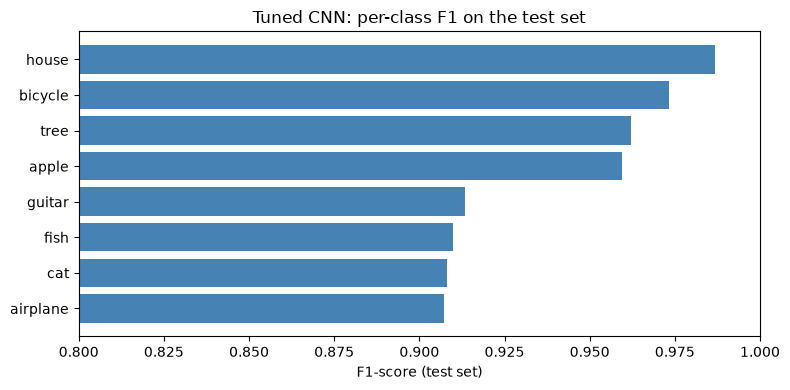

In [3]:
pc_p, pc_r, pc_f1, _ = precision_recall_fscore_support(y_test, test_pred, average=None)
per_class = pd.DataFrame({"class": categories, "precision": pc_p, "recall": pc_r, "f1": pc_f1}).round(4)
per_class.to_csv(results_dir / "quickdraw_cnn_per_class_test.csv", index=False)
display(per_class.sort_values("f1"))

order = np.argsort(pc_f1)
plt.figure(figsize=(8, 4))
plt.barh(np.array(categories)[order], pc_f1[order], color="steelblue")
plt.xlabel("F1-score (test set)")
plt.title("Tuned CNN: per-class F1 on the test set")
plt.xlim(min(0.8, pc_f1.min() - 0.02), 1.0)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_per_class_f1_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Confusion matrix (test)

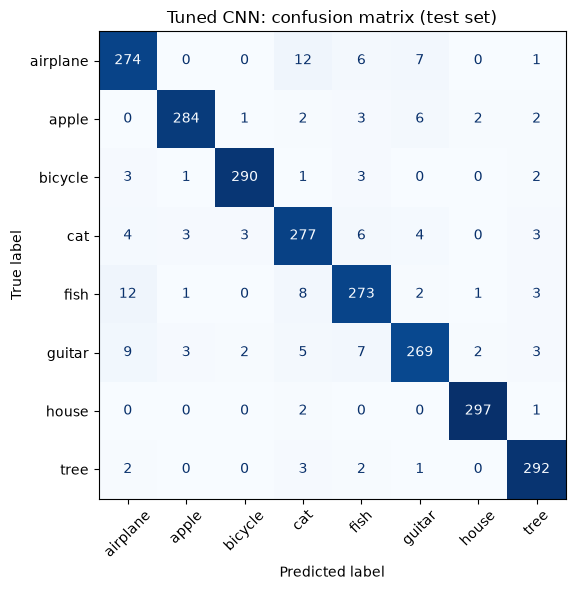

Most common confusions (true -> predicted : count):
  fish      -> airplane  : 12
  airplane  -> cat       : 12
  guitar    -> airplane  : 9
  fish      -> cat       : 8
  airplane  -> guitar    : 7


In [4]:
cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=categories).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Tuned CNN: confusion matrix (test set)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
top = np.argsort(off.ravel())[::-1][:5]
print("Most common confusions (true -> predicted : count):")
for t, pr in zip(*np.unravel_index(top, cm.shape)):
    print(f"  {categories[t]:9s} -> {categories[pr]:9s} : {off[t, pr]}")

From the confusion matrix we can see that the CNN does not spread its errors equally among the classes but rather among some pairs. Three of the five most frequent confusions involve the airplane: the airplane is predicted as a cat (12), the airoplane is predicted as a fish (12), and the guitar is predicted as an airoplane (9). The other two items in the top five are an airplane predicted as a guitar (7) and a fish predicted as a cat (8). Fish and airplane are the most confused pair with a total of 18 errors in both directions (12 + 6). This is probably because both are usually shown as a long horizontal shape with jutting features (usually fins or wings) and a tail on one end. At 28x28 the outlines can look nearly identical. The guitar and airplane could be confused for a similar reason. A long, thin neck intersecting a wider body can look like a plane body with wings. The lowest precision (0.894) of any class is cat, because it has the most false positives (33 test images incorrectly predicted as cat). This could be because cats are often drawn as a round shape with pointed ears and in rough sketches those pointed parts look like fish fins, tail fins and wing tips. The house (297/300) and tree (292/300) are easily recognisable and are very rarely confused with any other class. The bicycle (290/300) is very close behind. These explanations are only speculation since they rely on the usual way of drawing each class. We therefore verify them against the actual misclassified images in the misclassification grid.

## 4. Misclassification grid (test)

Misclassified: 144 of 2400 test images


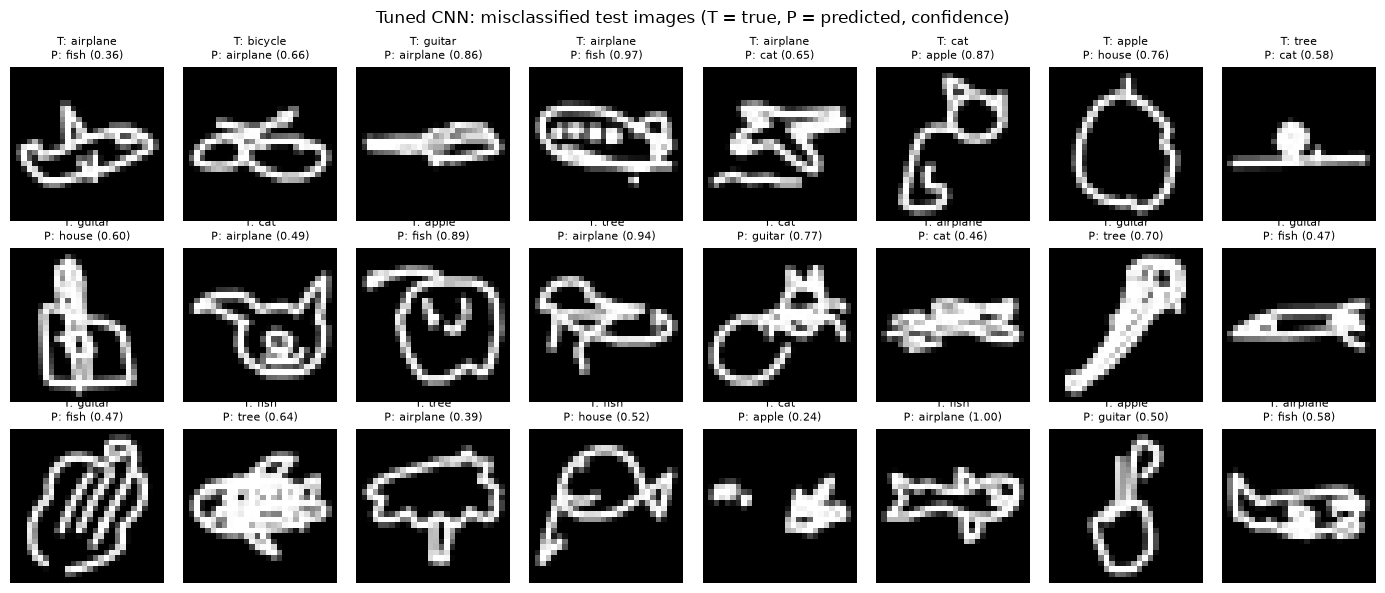

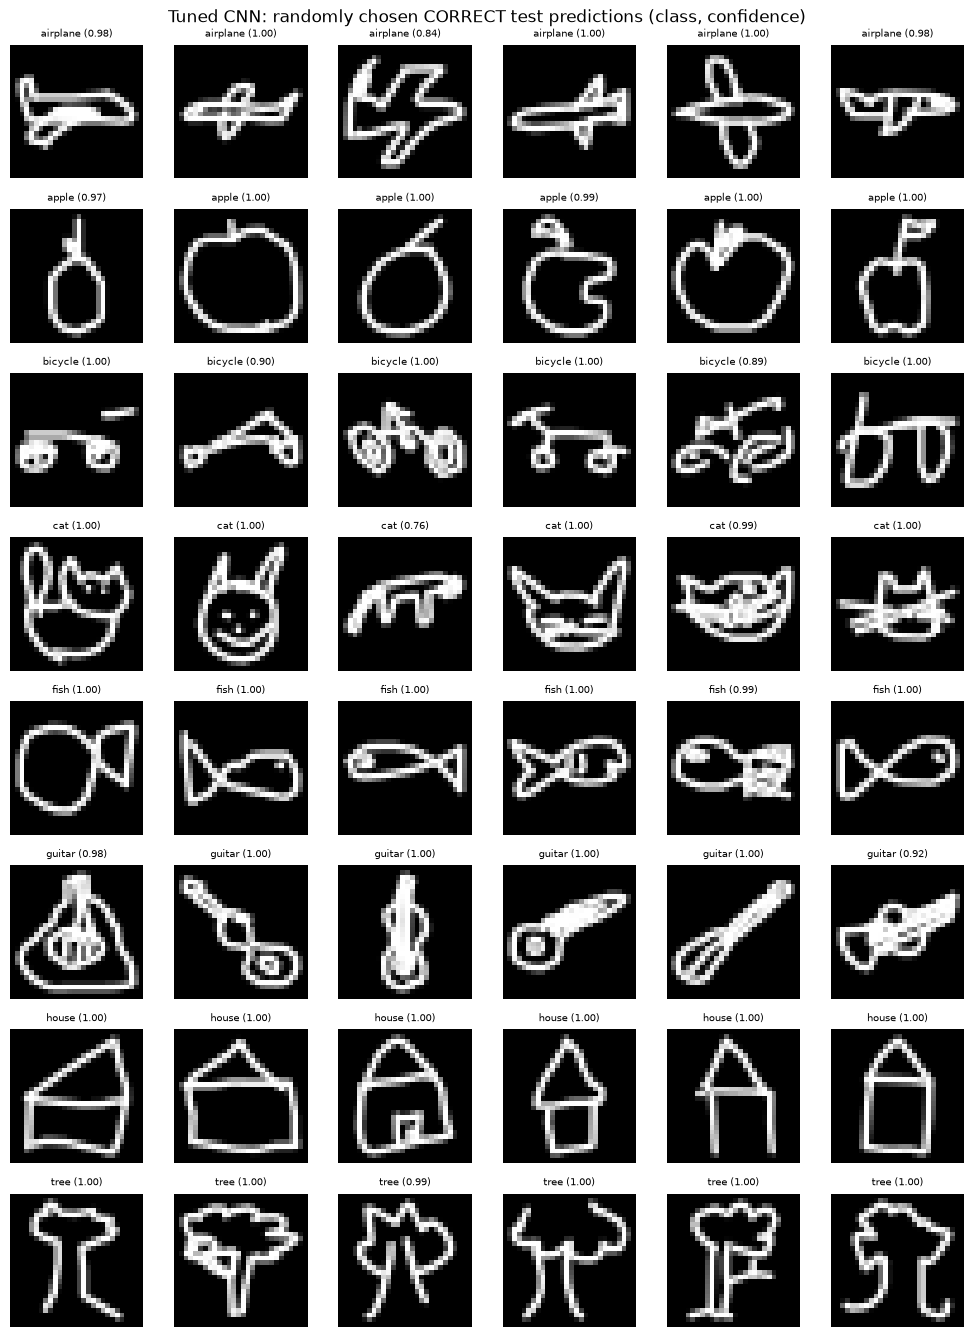

In [5]:
wrong = np.where(test_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} of {len(y_test)} test images")

rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(24, len(wrong)), replace=False)

fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"T: {categories[y_test[i]]}\nP: {categories[test_pred[i]]} ({test_probs[i].max():.2f})", fontsize=8)
fig.suptitle("Tuned CNN: misclassified test images (T = true, P = predicted, confidence)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_misclassified_test.png", dpi=150, bbox_inches="tight")
plt.show()

# Randomly chosen CORRECT test predictions: 6 per class, with the model's confidence
correct = np.where(test_pred == y_test)[0]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(categories), 6, figsize=(10, 1.7 * len(categories)))
for r, name in enumerate(categories):
    idx = correct[y_test[correct] == r]
    picks = rng.choice(idx, size=6, replace=False)
    for c, i in enumerate(picks):
        ax = axes[r, c]
        ax.imshow(X_test[i].squeeze(), cmap="gray")
        ax.set_title(f"{name} ({test_probs[i].max():.2f})", fontsize=7)
        ax.axis("off")
fig.suptitle("Tuned CNN: randomly chosen CORRECT test predictions (class, confidence)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_correct_test.png", dpi=150, bbox_inches="tight")
plt.show()

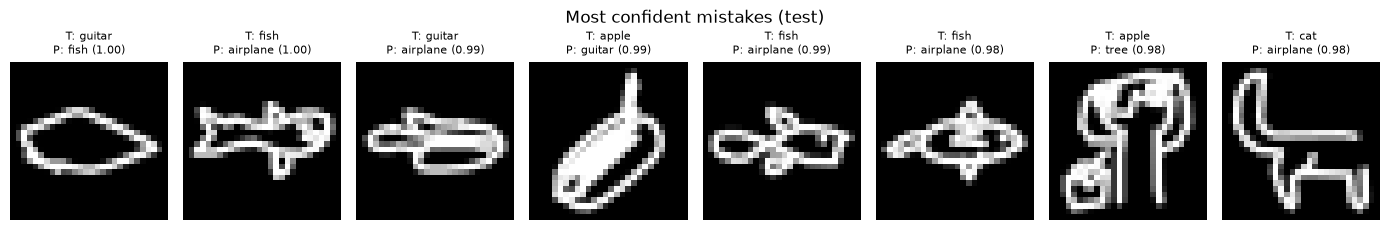

In [6]:
# The most confident mistakes are often the most informative (ambiguous or mislabelled drawings)
conf_wrong = wrong[np.argsort(test_probs[wrong].max(axis=1))[::-1][:8]]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, i in zip(axes, conf_wrong):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"T: {categories[y_test[i]]}\nP: {categories[test_pred[i]]} ({test_probs[i].max():.2f})", fontsize=8)
    ax.axis("off")
fig.suptitle("Most confident mistakes (test)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_confident_mistakes_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Final findings and limitations

The test set was run a single time at the end of the experiments. Our final CNN (run7) reached 0.94 accuracy and 0.94 macro F1. It had a third conv block with 32/64 filters, dropout 0.3, learning rate 0.001 and batch size 64. epoch 5 was picked by early stopping. This is 1.5 points lower than on the validation set (accuracy 0.955, macro F1 0.956). This small drop was expected, as the validation set was used to select the model and when to stop training.

The best results were obtained for house (F1 0.987), bicycle (0.973) and tree (0.962). They are pretty easy to spot because people draw them the same way every time. The classes with the lowest results were airoplane (0.907), cat (0.908), fish (0.910) and guitar (0.913). Most of the errors were made by a few couples. Fish and airplane were mixed up a combined 18 times. The airplane was a dozen cats. The guitar was classified nine times as an airplane. So we predicted the fish to be a cat 8 times. The class that was most mispredicted by the model was cat (33 times) with the least precision of 0.894 . We think these classes are often depicted as a long or round body with small pointy bits like wings, fins, tails or ears. In a rough 28x28 sketch these bits are very similar.

However there are some limitations of our work. We started with only 8 classes out of 345 classes. The more classes, particularly the similar ones like cat, dog and lion, the more difficult the task and the more likely the accuracy will be lower. Second, we sampled 3000 drawings per class from over 120k drawings, so we do not know how much more data would have helped the weaker classes. Third, we lose the order and timing of strokes when we turn the drawings into 28x28 images which could have helped to distinguish, for example, a fish from an airplane. Fourth, not all the mistakes are a model's fault, because some of the drawings are left incomplete or are difficult to recognise even for a human. Fifth, we use the same train/val/test split with seed 42. A different split might have a slight effect on the per-class scores, especially since we only have 300 test images per class. Finally, we only tuned a few hyper parameters, for a small number of runs and did not try things like data augmentation or learning rate schedules .